<a href="https://colab.research.google.com/github/kuz-hub/crm-cw1-sp500/blob/main/CRM_CW1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **CRM & CM Coursework 1: Market Analysis and Stock Segmentation Using RFM**
Study period: 1 Jan 2021 to 1 Jan 2025 (end date exclusive). Benchmark: S&P 500 index (^GSPC).

In [1]:
!pip install yfinance -q

In [2]:
# Import all required libraries
import os
import datetime
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("yfinance", yf.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

yfinance 0.2.66 | pandas 2.2.3 | numpy 2.4.6


# Task 1: Data Preparation and Feature Engineering
## 1.1 Ticker selection and data acquisition
Source of tickers: Wikipedia list of S&P 500 companies (read with pandas). Source of prices: yfinance (Yahoo Finance). I chose yfinance because it gives Close, Adjusted Close and Volume for each share in one call, as used in the Week 4 and 5 tutorials.

In [3]:
# Part 1: Extract the S&P 500 tickers from Wikipedia using pandas
# A User-Agent is needed, otherwise Wikipedia blocks the request (HTTP 403)
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
sp500_df = table[0]

# Yahoo uses '-' instead of '.' (BRK.B becomes BRK-B)
sp500_df['Symbol'] = sp500_df['Symbol'].str.replace('.', '-', regex=False)
tickers = sp500_df['Symbol'].tolist()

# Record the retrieval date
retrieval_date = datetime.date.today()
print('Retrieval date:', retrieval_date)
print('Total tickers extracted:', len(tickers))

sp500_df.to_csv(f'data/raw/tickers_{retrieval_date}.csv', index=False)
sp500_df[['Symbol', 'Security', 'GICS Sector']].head()

Retrieval date: 2026-11-14
Total tickers extracted: 503


,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology


In [4]:
# Part 2: Download daily data for all shares and the S&P 500 benchmark
# auto_adjust=False keeps both Close and Adj Close (Close is needed for Monetary)
start = '2021-01-01'
end = '2025-01-01'      # the end date is exclusive
all_symbols = tickers + ['^GSPC']

data = yf.download(all_symbols, start=start, end=end, auto_adjust=False)

adj_close = data['Adj Close']
close = data['Close']
volume = data['Volume']

print('Shapes:', adj_close.shape, close.shape, volume.shape)
print('Date range:', adj_close.index.min(), 'to', adj_close.index.max())
print('Symbols with no data at all:', adj_close.columns[adj_close.isna().all()].tolist())

[*********************100%***********************]  504 of 504 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['FDXF', 'VYLR', 'HONA', 'Q', 'SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Shapes: (1005, 504) (1005, 504) (1005, 504)
Date range: 2021-01-04 00:00:00 to 2024-12-31 00:00:00
Symbols with no data at all: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


In [5]:
# Save the raw data exactly as downloaded (preserved snapshot)
adj_close.to_csv('data/raw/adj_close_daily.csv')
close.to_csv('data/raw/close_daily.csv')
volume.to_csv('data/raw/volume_daily.csv')
print(os.listdir('data/raw'))

['close_daily.csv', 'tickers_2026-11-14.csv', 'adj_close_daily.csv', 'volume_daily.csv']


**If Yahoo is unavailable (cached copy):** the raw files above are saved in the GitHub repository. Run the next cell *instead of* the download cells to load them. The retrieval date for the cached files is 2026-11-08.

In [6]:
# OPTIONAL: load the cached raw data from GitHub (only if the live download fails)
# base = 'https://raw.githubusercontent.com/kuz-hub/crm-cw1-sp500/main/data/raw/'
# adj_close = pd.read_csv(base + 'adj_close_daily.csv', index_col=0, parse_dates=True)
# close = pd.read_csv(base + 'close_daily.csv', index_col=0, parse_dates=True)
# volume = pd.read_csv(base + 'volume_daily.csv', index_col=0, parse_dates=True)
# sp500_df = pd.read_csv(base + 'tickers_2026-11-08.csv')
# print(adj_close.shape)

## 1.2 Data validation and alignment
Checks: duplicate dates, missing values, non-positive prices, volume errors, unequal histories and corporate actions.

In [7]:
# Validation checks on the raw data
print('Duplicate dates:', adj_close.index.duplicated().sum(), '| sorted:', adj_close.index.is_monotonic_increasing)

missing = adj_close.isna().sum()
print('Tickers with missing Adj Close:', (missing > 0).sum())
print(missing[missing > 0].sort_values(ascending=False))

print('Missing-value mismatch, Adj Close vs Close:', (adj_close.isna() != close.isna()).sum().sum())
print('Missing-value mismatch, Close vs Volume:', (close.isna() != volume.isna()).sum().sum())
print('Non-positive Adj Close:', (adj_close <= 0).sum().sum(), '| Non-positive Close:', (close <= 0).sum().sum())
print('Negative volume:', (volume < 0).sum().sum())

zero_volume = (volume == 0).sum()
print('Zero-volume days per ticker:')
print(zero_volume[zero_volume > 0])

Duplicate dates: 0 | sorted: True
Tickers with missing Adj Close: 15
Ticker
FDXF    1005
Q       1005
HONA    1005
SNDK    1005
VYLR    1005
GEV      812
SOLV     811
RDDT     808
VLTO     692
GEHC     492
CEG      263
HOOD     143
APP       70
COIN      69
EXE       26
dtype: int64
Missing-value mismatch, Adj Close vs Close: 0
Missing-value mismatch, Close vs Volume: 0
Non-positive Adj Close: 0 | Non-positive Close: 0
Negative volume: 0
Zero-volume days per ticker:
Ticker
FERG      27
SW       424
^GSPC      1
dtype: int64


In [8]:
# Unequal histories: first valid date of each share
first_date = adj_close.apply(lambda s: s.first_valid_index())
late = first_date[first_date > adj_close.index.min()].sort_values()
print('Shares starting after', adj_close.index.min().date(), ':', len(late))
print(late)

Shares starting after 2021-01-04 : 10
Ticker
EXE    2021-02-10
COIN   2021-04-14
APP    2021-04-15
HOOD   2021-07-29
CEG    2022-01-19
GEHC   2022-12-15
VLTO   2023-10-04
RDDT   2024-03-21
SOLV   2024-03-26
GEV    2024-03-27
dtype: datetime64[ns]


In [9]:
# Corporate actions: dividends and splits
# If Adj Close / Close changes over time, the share paid dividends or had adjustments
ratio = adj_close / close
print('Shares with dividend adjustments (ratio changes):', (ratio.std() > 1e-9).sum())

# A split that was not adjusted would show as a big gap between Close return and Adj Close return
close_ret = close.pct_change(fill_method=None)
adj_ret = adj_close.pct_change(fill_method=None)
print('Largest gap between Close return and Adj Close return:', round((close_ret - adj_ret).abs().max().max(), 3))

# Very large one-day moves (above 40%), to check they are real price moves
jumps = (close_ret.abs() > 0.4).sum()
print('Shares with a daily Close move above 40%:', (jumps > 0).sum())
print(jumps[jumps > 0])

# On those days Close and Adj Close returns should agree (real moves, not unadjusted splits)
jump_gap = (close_ret - adj_ret).abs()[close_ret.abs() > 0.4].max().max()
print('Largest Close vs Adj Close return gap on those days:', f'{jump_gap:.2e}')


Shares with dividend adjustments (ratio changes): 405
Largest gap between Close return and Adj Close return: 0.059
Shares with a daily Close move above 40%: 7
Ticker
APP     1
BE      1
CVNA    5
DXCM    1
GL      1
HOOD    1
RDDT    1
dtype: int64
Largest Close vs Adj Close return gap on those days: 1.52e-08


**Validation rule:** a share is kept only if it has all sessions of Adj Close data in the study period and no zero-volume days. This gives every share the same period for mean return and beta, and real trading volume for RFM. Shares that fail are written to the exclusion log with a reason. Missing prices are **not** filled.

In [10]:
# Build the exclusion log
stocks = [c for c in adj_close.columns if c != '^GSPC']
n_days = len(adj_close)
log = []

for t in stocks:
    n_obs = adj_close[t].notna().sum()
    zero_days = int((volume[t] == 0).sum())
    if n_obs == 0:
        log.append((t, 'No price data for study period', 'Excluded'))
    elif n_obs < n_days:
        log.append((t, f'Incomplete history ({n_obs} of {n_days} sessions, first valid date {adj_close[t].first_valid_index().date()})', 'Excluded'))
    elif zero_days > 0:
        log.append((t, f'Zero-volume days ({zero_days})', 'Excluded'))

exclusion_log = pd.DataFrame(log, columns=['Ticker', 'Reason', 'Action'])
valid_stocks = [t for t in stocks if t not in exclusion_log['Ticker'].tolist()]

print('Shares downloaded:', len(stocks), '| excluded:', len(exclusion_log), '| valid:', len(valid_stocks))
exclusion_log.to_csv('data/processed/exclusion_log.csv', index=False)
exclusion_log

Shares downloaded: 503 | excluded: 17 | valid: 486


,Ticker,Reason,Action
0,APP,"Incomplete history (935 of 1005 sessions, firs...",Excluded
1,CEG,"Incomplete history (742 of 1005 sessions, firs...",Excluded
2,COIN,"Incomplete history (936 of 1005 sessions, firs...",Excluded
3,EXE,"Incomplete history (979 of 1005 sessions, firs...",Excluded
4,FDXF,No price data for study period,Excluded
5,FERG,Zero-volume days (27),Excluded
6,GEHC,"Incomplete history (513 of 1005 sessions, firs...",Excluded
7,GEV,"Incomplete history (193 of 1005 sessions, firs...",Excluded
8,HONA,No price data for study period,Excluded
9,HOOD,"Incomplete history (862 of 1005 sessions, firs...",Excluded


In [11]:
# Keep only the valid shares (plus the benchmark) in all three tables
keep = valid_stocks + ['^GSPC']
adj_close = adj_close[keep]
close = close[keep]
volume = volume[keep]

# Observation date = the last trading date that all kept series share
observation_date = adj_close.dropna().index.max()
print('Observation date:', observation_date.date())
print('Tables:', adj_close.shape, close.shape, volume.shape)

Observation date: 2024-12-31
Tables: (1005, 487) (1005, 487) (1005, 487)


## 1.3 Weekly return and weekly beta
Weekly prices use the last available Adjusted Close in each Friday-ending week. Weekly return = this week's price / previous week's price - 1. The first and last calendar weeks are dropped if they are incomplete.

In [12]:
# Weekly returns (same method as the Week 4/5 tutorials, but with no gap filling)
def calculate_weekly_returns(prices):
    weekly_prices = prices.resample('W-FRI').last()

    # Keep only complete calendar weeks: Monday of the week must be on/after the first date,
    # and the Friday label must be on/before the last date
    first_day = prices.index.min()
    last_day = prices.index.max()
    monday = weekly_prices.index - pd.Timedelta(days=4)
    complete = (monday >= first_day) & (weekly_prices.index <= last_day)
    weekly_prices = weekly_prices[complete]

    # pct_change = this week / previous week - 1; the first week has no previous week
    return weekly_prices.pct_change(fill_method=None).iloc[1:]

weekly_returns_all = calculate_weekly_returns(adj_close)
market_returns = weekly_returns_all['^GSPC']
weekly_returns = weekly_returns_all[valid_stocks]

print('Weekly return table:', weekly_returns.shape)
print('First week:', weekly_returns.index.min().date(), '| last week:', weekly_returns.index.max().date())
print('Missing weekly returns:', weekly_returns.isna().sum().sum())

Weekly return table: (207, 486)
First week: 2021-01-15 | last week: 2024-12-27
Missing weekly returns: 0


In [13]:
# Mean weekly return (arithmetic mean over the full period)
mean_return = weekly_returns.mean().rename('Mean_Weekly_Return')
print(mean_return.describe())

count    486.000000
mean       0.002857
std        0.002652
min       -0.004468
25%        0.001182
50%        0.002619
75%        0.004207
max        0.017772
Name: Mean_Weekly_Return, dtype: float64


In [14]:
# Weekly beta = covariance(share, market) / variance(market), on matched weeks (same function as the tutorial)
def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):
    results = []
    for share in weekly_returns.columns:
        paired = pd.concat(
            [weekly_returns[share].rename('share'), market_returns.rename('market')],
            axis=1
        ).replace([np.inf, -np.inf], np.nan).dropna()

        variance = paired['market'].var(ddof=1)
        beta = np.nan
        if len(paired) >= min_weeks and variance > 0:
            beta = paired['share'].cov(paired['market']) / variance

        results.append({'Share': share, 'Beta': beta, 'Paired_weeks': len(paired)})
    return pd.DataFrame(results).set_index('Share')

beta_df = calculate_weekly_beta(weekly_returns, market_returns)
print('Aligned weekly observations used for beta:', beta_df['Paired_weeks'].unique())
print(beta_df['Beta'].describe())
beta_df.head()

Aligned weekly observations used for beta: [207]
count    486.000000
mean       0.973695
std        0.407339
min        0.055453
25%        0.666599
50%        0.950610
75%        1.179538
max        3.778560
Name: Beta, dtype: float64


,Beta,Paired_weeks
Share,,
A,1.074723,207
AAPL,1.174836,207
ABBV,0.425366,207
ABNB,1.472709,207
ABT,0.583543,207


In [15]:
# Independent check of one share (AAPL) with numpy
x = weekly_returns['AAPL'].values
y = market_returns.values
check_beta = np.cov(x, y)[0, 1] / np.var(y, ddof=1)
print('AAPL beta from function:', round(beta_df.loc['AAPL', 'Beta'], 4))
print('AAPL beta from numpy check:', round(check_beta, 4))
print('AAPL mean weekly return:', round(mean_return['AAPL'], 5))

AAPL beta from function: 1.1748
AAPL beta from numpy check: 1.1748
AAPL mean weekly return: 0.00393


In [ ]:
print('Aligned weekly observations:', len(weekly_returns))
print('Share and benchmark week labels identical:', weekly_returns.index.equals(market_returns.index))

## 1.4 Adapted RFM calculations (volume based)
- **High-volume day:** volume > 2 x the mean volume of the previous 20 sessions (the day itself is excluded using `shift(1)`).
- **R (Recency):** calendar days from the latest high-volume day to the observation date (missing if no event, never 0).
- **F (Frequency):** number of high-volume days in the latest 60 sessions.
- **M (Monetary):** sum of Close x Volume over the latest 60 sessions (USD).

In [16]:
# RFM for every valid share (same logic as the Week 3 tutorial loop)
results = []

for ticker in valid_stocks:
    vol = volume[ticker]
    price = close[ticker]

    # Mean of the previous 20 sessions, excluding the day being tested
    average_volume = vol.shift(1).rolling(20).mean()
    high_volume = vol > 2 * average_volume

    # Only days that have a full 20-session baseline can count as an event
    event_days = vol.index[high_volume & average_volume.notna()]

    # Latest 60 trading sessions ending on the observation date
    last60 = vol.index[-60:]

    if len(event_days) > 0:
        recency = (observation_date - event_days[-1]).days
    else:
        recency = np.nan          # no event: missing, not 0

    results.append({
        'Share': ticker,
        'Recency': recency,
        'Frequency': int(high_volume.loc[last60].sum()),
        'Monetary': float((price.loc[last60] * vol.loc[last60]).sum()),
        'History_sessions': int(vol.notna().sum())
    })

rfm = pd.DataFrame(results).set_index('Share')
print('Shares with no high-volume event (Recency missing):', rfm['Recency'].isna().sum())
print(rfm.describe().round(2))
rfm.head()

Shares with no high-volume event (Recency missing): 0
       Recency  Frequency      Monetary  History_sessions
count   486.00     486.00  4.860000e+02             486.0
mean     20.41       2.99  3.940419e+10            1005.0
std      21.34       1.33  1.291388e+11               0.0
min       4.00       0.00  1.297483e+09            1005.0
25%      11.00       2.00  1.019517e+10            1005.0
50%      11.00       3.00  1.668382e+10            1005.0
75%      14.75       4.00  3.227689e+10            1005.0
max     222.00       8.00  1.847697e+12            1005.0


,Recency,Frequency,Monetary,History_sessions
Share,,,,
A,11,2,1.400180e+10,1005
AAPL,11,2,6.233034e+11,1005
ABBV,11,3,6.837054e+10,1005
ABNB,11,3,3.652850e+10,1005
ABT,11,1,3.523027e+10,1005


### 1.4.1 Worked example and evidence for one share (AAPL)
A hand-style check with a plain loop, to confirm the table above is correct.

In [17]:
# Worked example: AAPL
share = 'AAPL'
vol = volume[share]
price = close[share]
average_volume = vol.shift(1).rolling(20).mean()
high_volume = vol > 2 * average_volume

print('Observation date:', observation_date.date())
print('Last 60 sessions run from', vol.index[-60].date(), 'to', vol.index[-1].date())

# Threshold example for the last session
last_day = vol.index[-1]
print('Previous 20-session mean volume:', round(average_volume.iloc[-1]))
print('Threshold (2 x mean):', round(2 * average_volume.iloc[-1]))
print('Volume on', last_day.date(), ':', vol.iloc[-1])

# Latest high-volume day (use only days with a full 20-session baseline)
event_days = vol.index[high_volume & average_volume.notna()]
print('Latest high-volume day:', event_days[-1].date())
print('R =', (observation_date - event_days[-1]).days, 'calendar days')

# F and M with a plain loop over the last 60 sessions
f_count = 0
m_total = 0.0
for day in vol.index[-60:]:
    if high_volume[day]:
        f_count += 1
    m_total += price[day] * vol[day]
print('F =', f_count, '| M =', round(m_total))

print('Table values:', rfm.loc[share, ['Recency', 'Frequency', 'Monetary']].to_dict())

Observation date: 2024-12-31
Last 60 sessions run from 2024-10-07 to 2024-12-31
Previous 20-session mean volume: 46921770
Threshold (2 x mean): 93843540
Volume on 2024-12-31 : 39480700
Latest high-volume day: 2024-12-20
R = 11 calendar days
F = 2 | M = 623303377707
Table values: {'Recency': 11.0, 'Frequency': 2.0, 'Monetary': 623303377706.5842}


In [ ]:
# Edge case checks
print('Shares with at least 80 sessions of history (20 baseline + 60 window):', (rfm['History_sessions'] >= 80).sum(), 'of', len(rfm))
print('Shares with a missing Recency (no event):')
print(rfm[rfm['Recency'].isna()])
print('Shares with Frequency 0:', (rfm['Frequency'] == 0).sum())
print('Observation date has data for every kept share:', adj_close.loc[observation_date].notna().all())

## 1.5 Metric interpretation
- **Mean weekly return:** average past weekly gain or loss. It describes 2021-2024 only and does not predict future returns.
- **Beta:** how much the share moved when the market moved. Above 1 is more sensitive than the index, below 1 less. It is an estimate from 207 weeks.
- **Recency:** days since the latest unusually busy trading day. Low means recent activity, high means the share has been quiet. It depends on the single observation date.
- **Frequency:** number of busy days in the latest 60 sessions. It counts days, not individual trades.
- **Monetary:** approximate traded value (Close x Volume) over the latest 60 sessions. It is a liquidity and size proxy, not market capitalisation, profit or net investment inflow.

None of these measures shows whether buyers or sellers drove a volume spike, so they describe activity, not performance.

In [18]:
# Final feature table: one row per share (only shares with a valid RFM, so every clustering uses the same shares)
features = pd.concat([mean_return, beta_df[['Beta', 'Paired_weeks']], rfm[['Recency', 'Frequency', 'Monetary']]], axis=1)
features = features.join(sp500_df.set_index('Symbol')[['Security', 'GICS Sector']])

rfm_excluded = features[features['Recency'].isna()].index.tolist()
print('Shares dropped from the common set because Recency is missing:', rfm_excluded)
features = features.dropna(subset=['Mean_Weekly_Return', 'Beta', 'Recency', 'Frequency', 'Monetary'])
features.index.name = 'Share'

print('Final common share set:', len(features))
features.to_csv('data/processed/feature_table.csv')
features.describe().round(3)

Shares dropped from the common set because Recency is missing: []
Final common share set: 486


,Mean_Weekly_Return,Beta,Paired_weeks,Recency,Frequency,Monetary
count,486.000,486.000,486.0,486.000,486.000,4.860000e+02
mean,0.003,0.974,207.0,20.407,2.990,3.940419e+10
std,0.003,0.407,0.0,21.342,1.331,1.291388e+11
min,-0.004,0.055,207.0,4.000,0.000,1.297483e+09
25%,0.001,0.667,207.0,11.000,2.000,1.019517e+10
50%,0.003,0.951,207.0,11.000,3.000,1.668382e+10
75%,0.004,1.180,207.0,14.750,4.000,3.227689e+10
max,0.018,3.779,207.0,222.000,8.000,1.847697e+12


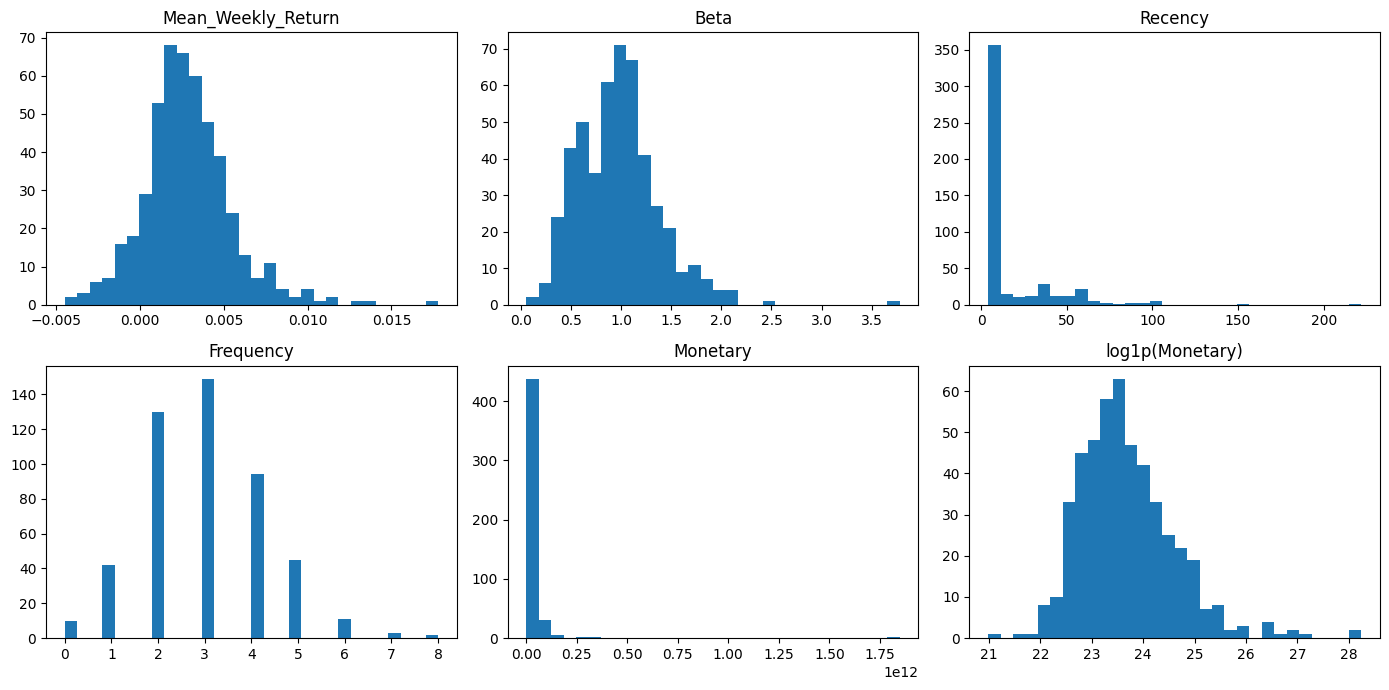

Skewness:
Mean_Weekly_Return     0.87
Beta                   1.10
Recency                3.65
Frequency              0.42
Monetary              11.68
dtype: float64


In [19]:
# Distribution plots of the features (skew and outlier check)
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flatten(), ['Mean_Weekly_Return', 'Beta', 'Recency', 'Frequency', 'Monetary']):
    ax.hist(features[col], bins=30)
    ax.set_title(col)
axes.flatten()[5].hist(np.log1p(features['Monetary']), bins=30)
axes.flatten()[5].set_title('log1p(Monetary)')
plt.tight_layout()
plt.savefig('outputs/feature_distributions.png', dpi=150)
plt.show()
print('Skewness:')
print(features[['Mean_Weekly_Return', 'Beta', 'Recency', 'Frequency', 'Monetary']].skew().round(2))

# Task 2: Stock Segmentation and Sensitivity Analysis
## 2.1 Feature preparation
Two separate feature matrices (not combined into one score):
- **Risk and return:** mean weekly return and weekly beta
- **Trading activity:** Recency, Frequency and Monetary

Each matrix is clustered with Ward agglomerative clustering and with K-Means, giving four baseline solutions.

In [20]:
# Extra libraries for clustering
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

pd.set_option('display.max_colwidth', None)   # show full text in tables
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', None)

import scipy, sklearn
print('scipy', scipy.__version__, '| scikit-learn', sklearn.__version__)


scipy 1.16.3 | scikit-learn 1.6.1


In [21]:
# Two separate feature matrices (same 486 shares in both)
risk_return = features[['Mean_Weekly_Return', 'Beta']].copy()
activity = features[['Recency', 'Frequency', 'Monetary']].copy()
print('Shares in both matrices:', len(risk_return), len(activity))

# Inspect skew and outliers (outlier = beyond 1.5 x IQR from the quartiles)
for name, table in [('Risk and return', risk_return), ('Trading activity', activity)]:
    print(name)
    for col in table.columns:
        q1, q3 = table[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        n_out = ((table[col] < q1 - 1.5 * iqr) | (table[col] > q3 + 1.5 * iqr)).sum()
        print(f'   {col}: skew = {table[col].skew():.2f}, outliers = {n_out}')

Shares in both matrices: 486 486
Risk and return
   Mean_Weekly_Return: skew = 0.87, outliers = 15
   Beta: skew = 1.10, outliers = 10
Trading activity
   Recency: skew = 3.65, outliers = 115
   Frequency: skew = 0.42, outliers = 2
   Monetary: skew = 11.68, outliers = 45


**Treatment of skewed variables:** Monetary is extremely skewed (a few very heavily traded shares), so `log1p` is applied to it before standardising. Mean weekly return, beta, Recency and Frequency have moderate skew and keep their natural meaning (a return, a market sensitivity, days, a count), so they are only standardised. Their outliers are real shares (for example high-beta or long-dormant shares) and are kept, because removing them would hide the groups I want to find.

In [22]:
# log1p on Monetary, then standardise each matrix (mean 0, spread 1)
activity['Monetary'] = np.log1p(activity['Monetary'])
print('Monetary skew after log1p:', round(activity['Monetary'].skew(), 2))

X_rr = pd.DataFrame(StandardScaler().fit_transform(risk_return), index=risk_return.index, columns=risk_return.columns)
X_act = pd.DataFrame(StandardScaler().fit_transform(activity), index=activity.index, columns=activity.columns)
print(X_rr.describe().round(2).loc[['mean', 'std']])
print(X_act.describe().round(2).loc[['mean', 'std']])

Monetary skew after log1p: 1.08
      Mean_Weekly_Return  Beta
mean                 0.0   0.0
std                  1.0   1.0
      Recency  Frequency  Monetary
mean     -0.0       -0.0      -0.0
std       1.0        1.0       1.0


## 2.2 Agglomerative clustering (Ward linkage, Euclidean distance)
**Suitability:** agglomerative clustering builds a tree by merging the two most similar groups, so it needs no k in advance and the dendrogram shows the structure. Ward linkage merges the pair that adds the least spread inside the new group, which gives compact groups. **Limitations:** merges can never be undone (greedy), it is sensitive to outliers, and it becomes slow on very large data (fine for 486 shares).

In [ ]:
# Ward linkage on the standardised features (one dendrogram per matrix)
Z_rr = linkage(X_rr, method='ward')
Z_act = linkage(X_act, method='ward')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
dendrogram(Z_rr, no_labels=True, ax=axes[0])
axes[0].set_title('Ward dendrogram: risk and return')
axes[0].set_ylabel('Ward linkage distance')
dendrogram(Z_act, no_labels=True, ax=axes[1])
axes[1].set_title('Ward dendrogram: trading activity (R, F, log M)')
axes[1].set_ylabel('Ward linkage distance')
plt.tight_layout()
plt.savefig('outputs/dendrograms.png', dpi=150)
plt.show()

In [ ]:
# Compare k = 2 to 8: silhouette score, cluster sizes
def compare_ward(X, Z):
    rows = []
    for k in range(2, 9):
        labels = cut_tree(Z, n_clusters=k).ravel()
        sizes = np.bincount(labels)
        rows.append({'k': k, 'Silhouette': round(silhouette_score(X, labels), 3),
                     'Smallest_cluster': sizes.min(), 'Smallest_%': round(100 * sizes.min() / len(X), 1),
                     'Sizes': sorted(sizes.tolist(), reverse=True)})
    return pd.DataFrame(rows).set_index('k')

ward_rr_table = compare_ward(X_rr, Z_rr)
ward_act_table = compare_ward(X_act, Z_act)
print('Ward: risk and return'); print(ward_rr_table)
print('Ward: trading activity'); print(ward_act_table)

## 2.3 K-Means clustering
**Suitability:** K-Means is fast and gives compact, similar-sized groups when the features are numeric and standardised. **Limitations:** k must be chosen in advance, it is sensitive to outliers and to the starting centres, and it assumes round groups. To reduce the starting-point problem I fix a random seed and run 20 initialisations for every k (`n_init=20`).

In [ ]:
# Compare k = 2 to 8: silhouette, inertia and sizes (seed 42, 20 initialisations)
def compare_kmeans(X):
    rows = []
    for k in range(2, 9):
        km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
        sizes = np.bincount(km.labels_)
        rows.append({'k': k, 'Silhouette': round(silhouette_score(X, km.labels_), 3),
                     'Inertia': round(km.inertia_, 1),
                     'Smallest_cluster': sizes.min(), 'Smallest_%': round(100 * sizes.min() / len(X), 1),
                     'Sizes': sorted(sizes.tolist(), reverse=True)})
    return pd.DataFrame(rows).set_index('k')

km_rr_table = compare_kmeans(X_rr)
km_act_table = compare_kmeans(X_act)
print('K-Means: risk and return'); print(km_rr_table)
print('K-Means: trading activity'); print(km_act_table)

In [ ]:
# Silhouette and inertia against k (elbow plot)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for table, label in [(ward_rr_table, 'Ward, risk-return'), (km_rr_table, 'K-Means, risk-return'),
                     (ward_act_table, 'Ward, activity'), (km_act_table, 'K-Means, activity')]:
    axes[0].plot(table.index, table['Silhouette'], marker='o', label=label)
axes[0].set_title('Silhouette score by k'); axes[0].set_xlabel('k'); axes[0].legend(fontsize=8)
axes[1].plot(km_rr_table.index, km_rr_table['Inertia'], marker='o')
axes[1].set_title('K-Means inertia: risk and return'); axes[1].set_xlabel('k')
axes[2].plot(km_act_table.index, km_act_table['Inertia'], marker='o')
axes[2].set_title('K-Means inertia: trading activity'); axes[2].set_xlabel('k')
plt.tight_layout()
plt.savefig('outputs/k_selection.png', dpi=150)
plt.show()

### Choosing k
Rule used for all four solutions: **k of at least 3, the highest average silhouette across Ward and K-Means, and no cluster smaller than about 5% of the shares.** k = 2 has the highest silhouette in every table, but it only separates one smaller group from the rest, which is too coarse to be useful, so it is noted but not chosen. Larger k values (6 to 8) produce clusters of only a handful of shares.

- **Risk and return: k = 5.** It has the best silhouette for both methods among k = 3 to 5, and the smallest cluster stays above 5%.
- **Trading activity: k = 4.** k = 5 and 6 score slightly higher but create clusters of only 10 to 11 shares. k = 4 keeps balanced groups.

All silhouette scores are modest (about 0.28 to 0.34), so the groups are best read as useful descriptions along a continuum, not sharply separated types. The dendrogram colour threshold is not used on its own to choose k.

In [ ]:
# Chosen number of clusters
k_rr = 5
k_act = 4

# Fit the four baseline solutions
labels_ward_rr = cut_tree(Z_rr, n_clusters=k_rr).ravel() + 1
labels_ward_act = cut_tree(Z_act, n_clusters=k_act).ravel() + 1
labels_km_rr = KMeans(n_clusters=k_rr, n_init=20, random_state=42).fit_predict(X_rr) + 1
labels_km_act = KMeans(n_clusters=k_act, n_init=20, random_state=42).fit_predict(X_act) + 1

results = features.copy()
results['Ward_RiskReturn'] = labels_ward_rr
results['KMeans_RiskReturn'] = labels_km_rr
results['Ward_Activity'] = labels_ward_act
results['KMeans_Activity'] = labels_km_act
results.to_csv('data/processed/cluster_assignments.csv')
results[['Security', 'GICS Sector', 'Ward_RiskReturn', 'KMeans_RiskReturn', 'Ward_Activity', 'KMeans_Activity']].head()

## 2.4 Cluster profiles (original units) and algorithm comparison

In [ ]:
# Profiles in ORIGINAL units (not standardised): cluster averages and sizes
rr_cols = ['Mean_Weekly_Return', 'Beta']
act_cols = ['Recency', 'Frequency', 'Monetary']

def profile(label_col, cols):
    table = results.groupby(label_col)[cols].mean()
    table['Shares'] = results.groupby(label_col).size()
    if 'Monetary' in table.columns:
        table['Monetary'] = table['Monetary'] / 1e9      # USD billions
        table = table.rename(columns={'Monetary': 'Monetary_USD_bn'})
    return table.round(3)

for label, cols in [('Ward_RiskReturn', rr_cols), ('KMeans_RiskReturn', rr_cols),
                    ('Ward_Activity', act_cols), ('KMeans_Activity', act_cols)]:
    print(label); print(profile(label, cols)); print()

profile('Ward_RiskReturn', rr_cols).to_csv('data/processed/profile_ward_riskreturn.csv')
profile('KMeans_RiskReturn', rr_cols).to_csv('data/processed/profile_kmeans_riskreturn.csv')
profile('Ward_Activity', act_cols).to_csv('data/processed/profile_ward_activity.csv')
profile('KMeans_Activity', act_cols).to_csv('data/processed/profile_kmeans_activity.csv')

In [ ]:
# Labelled 2D visualisation
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# Risk and return: the two original features are plotted directly (no dimension reduction)
for ax, col, title in [(axes[0, 0], 'Ward_RiskReturn', 'Ward'), (axes[0, 1], 'KMeans_RiskReturn', 'K-Means')]:
    sns.scatterplot(data=results, x='Beta', y='Mean_Weekly_Return', hue=col, palette='tab10', ax=ax)
    ax.set_title(f'Risk and return clusters ({title}, k={k_rr})')
    ax.set_xlabel('Weekly beta'); ax.set_ylabel('Mean weekly return')

# Trading activity: three features reduced to two with PCA (first two principal components)
pca = PCA(n_components=2)
coords = pca.fit_transform(X_act)
results['PC1'], results['PC2'] = coords[:, 0], coords[:, 1]
print('PCA explained variance (PC1, PC2):', pca.explained_variance_ratio_.round(2))
for ax, col, title in [(axes[1, 0], 'Ward_Activity', 'Ward'), (axes[1, 1], 'KMeans_Activity', 'K-Means')]:
    sns.scatterplot(data=results, x='PC1', y='PC2', hue=col, palette='tab10', ax=ax)
    ax.set_title(f'Trading activity clusters ({title}, k={k_act}, PCA view)')
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)')
    for share in results['Monetary'].nlargest(5).index:      # label the five most traded shares
        ax.annotate(share, (results.loc[share, 'PC1'], results.loc[share, 'PC2']), fontsize=8)
plt.tight_layout()
plt.savefig('outputs/cluster_plots.png', dpi=150)
plt.show()

In [ ]:
# Compare the two algorithms on the same shares (adjusted Rand index: 1 = identical, 0 = random)
ari_rr = adjusted_rand_score(results['Ward_RiskReturn'], results['KMeans_RiskReturn'])
ari_act = adjusted_rand_score(results['Ward_Activity'], results['KMeans_Activity'])
print('Adjusted Rand index Ward vs K-Means, risk and return:', round(ari_rr, 3))
print('Adjusted Rand index Ward vs K-Means, trading activity:', round(ari_act, 3))

print('Risk and return: Ward (rows) vs K-Means (columns)')
print(pd.crosstab(results['Ward_RiskReturn'], results['KMeans_RiskReturn']))
print('Trading activity: Ward (rows) vs K-Means (columns)')
print(pd.crosstab(results['Ward_Activity'], results['KMeans_Activity']))

In [ ]:
# Sector composition of each cluster (share of each cluster in each GICS sector, in %)
for label in ['KMeans_RiskReturn', 'KMeans_Activity']:
    sector_table = (pd.crosstab(results[label], results['GICS Sector'], normalize='index') * 100).round(1)
    print(label); print(sector_table); print()
    sector_table.plot(kind='bar', stacked=True, figsize=(11, 4), colormap='tab20')
    plt.title(f'Sector mix of each cluster: {label}')
    plt.ylabel('% of shares'); plt.xlabel('Cluster')
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=7)
    plt.tight_layout()
    plt.savefig(f'outputs/sector_mix_{label}.png', dpi=150)
    plt.show()

## 2.5 RFM sensitivity and correlated inputs
### 2.5.1 Correlation analysis
Standardising gives every feature the same spread, but it does not remove correlation between features. If two inputs move together, they carry partly the same information, so that information counts more than once in the distance and pulls the clusters towards it. A high correlation alone does not prove one feature dominates the clustering.

In [ ]:
# Correlations among Recency, Frequency and log1p(Monetary)
corr = activity[['Recency', 'Frequency', 'Monetary']].rename(columns={'Monetary': 'log1p_Monetary'}).corr().round(3)
print(corr)

plt.figure(figsize=(5, 4))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation of RFM inputs')
plt.tight_layout()
plt.savefig('outputs/rfm_correlations.png', dpi=150)
plt.show()

### 2.5.2 Removing Monetary
The chosen Ward RFM solution is repeated with Recency and Frequency only (same shares, same k, standardised again), and compared with the original using the adjusted Rand index. Traded value (Monetary) is only a liquidity proxy: bid-ask spread and price impact are not measured here.

In [ ]:
# Ward on R and F only (same shares, same k, standardised afresh)
X_rf = pd.DataFrame(StandardScaler().fit_transform(features[['Recency', 'Frequency']]),
                    index=features.index, columns=['Recency', 'Frequency'])
Z_rf = linkage(X_rf, method='ward')
results['Ward_Activity_RF_only'] = cut_tree(Z_rf, n_clusters=k_act).ravel() + 1

ari_rf = adjusted_rand_score(results['Ward_Activity'], results['Ward_Activity_RF_only'])
print('Adjusted Rand index, Ward RFM vs Ward R+F only:', round(ari_rf, 3))
print('Membership overlap (rows = RFM clusters, columns = R+F only clusters):')
print(pd.crosstab(results['Ward_Activity'], results['Ward_Activity_RF_only']))

In [ ]:
# Does Monetary mainly separate activity or liquidity (traded value)?
for label in ['Ward_Activity', 'Ward_Activity_RF_only']:
    table = results.groupby(label).agg(Shares=('Monetary', 'size'),
                                       Recency=('Recency', 'mean'),
                                       Frequency=('Frequency', 'mean'),
                                       Median_traded_value_USD_bn=('Monetary', lambda s: s.median() / 1e9))
    print(label); print(table.round(2)); print()

results.to_csv('data/processed/cluster_assignments.csv')
print('Saved cluster_assignments.csv with', results.shape[1], 'columns')